# Récords NBA, parte II: los que todos quieren y los que nadie quiere

**EDA: análisis exploratorio de datos.**

Un jugador puede hacer historia metiendo triples. Un equipo también puede hacerla perdiendo casi todas las noches. Las dos cosas dejan una línea nueva en el libro de récords, pero solo una se celebra.

En esta segunda parte busco **qué marcas de club merece la pena seguir en 2026-27, tanto por lo bueno como por lo malo**. Comparo cinco récords positivos y cinco negativos con lo ocurrido en 2025-26. Después miro tres formas distintas de tocar fondo: acumular derrotas, encadenarlas y ganar muy pocos partidos en proporción a los disputados.

### Por dónde voy a pasar

1. Reúno los datos y corrijo las marcas equivocadas del archivo anterior.
2. Comparo triples, asistencias y tapones con los récords de cada club.
3. Busco los equipos que vienen de una temporada cercana a su peor año.
4. Explico por qué 59 derrotas pueden ser peores que 73.
5. Compruebo cuánto puede cambiar un equipo en dos temporadas.

### Cuatro palabras para seguir el cuaderno

- **Franquicia:** un club y su historia, aunque cambie de ciudad o de nombre. Incluyo a los antiguos New Jersey Nets dentro de la historia de Brooklyn.
- **Temporada regular:** los partidos de liga anteriores a las eliminatorias por el título. No mezclo ambas fases.
- **Asistencia:** un pase que termina directamente en una canasta de un compañero.
- **Tapón:** una acción defensiva que bloquea el lanzamiento del rival.

Tomo los datos hasta el cierre de 2025-26 y consulto las fuentes el 19 de octubre de 2026. La temporada 2026-27 empieza de cero: las cifras del año anterior sirven para comparar, no se arrastran al nuevo curso.

## 1. Vuelvo a las fuentes

Parto del radar de la primera entrega, pero no me quedo con sus 15 filas de reserva: todas eran positivas. Busco también los récords negativos y reviso las cifras antes de compararlas.

Elijo cinco casos positivos para mirar tres cosas diferentes: triples de jugadores, pases de un equipo y tapones. Para las derrotas, elijo los cinco equipos que menos partidos ganaron en 2025-26: Washington, Indiana, Brooklyn, Utah y Sacramento. Esta selección permite contar historias distintas; no pretende clasificar las opciones de todos los clubes.

Utilizo notas estadísticas, guías y noticias de la NBA y de los equipos. Guardo seis PDF en `fuentes/` y dejo todos los enlaces en `auditoria_fuentes.csv`. Para Golden State conservo además la serie histórica de Basketball-Reference que figuraba en el radar.

Cada fila de `records_segunda_parte.csv` describe una marca: quién la persigue, qué consiguió en 2025-26, cuántos partidos jugó, dónde está el récord y de qué temporada viene. En los récords de club utilizo su etapa NBA; no añado los años de la antigua liga ABA.

In [1]:
# leo los datos que dejo junto al cuaderno para poder repetir el análisis sin conexión
from pathlib import Path
import html
import json
import hashlib
import platform
import pandas as pd
from IPython.display import display, SVG, HTML

ruta = Path.cwd()
datos = pd.read_csv(ruta / 'records_segunda_parte.csv')
fuentes = pd.read_csv(ruta / 'auditoria_fuentes.csv').fillna('')
historicas = pd.read_csv(ruta / 'temporadas_historicas.csv')
detroit = pd.read_csv(ruta / 'evolucion_detroit.csv')
radar_anterior = pd.read_csv(ruta / 'radar_records_nba_2026_27.csv')
print(f'Python {platform.python_version()} | pandas {pd.__version__}')
print(f'Analizo {len(datos)} marcas: {(datos.tipo == "Positivo").sum()} positivas y {(datos.tipo == "Negativo").sum()} negativas.')

# muestro nombres claros en las tablas sin cambiar las columnas que utilizo en el código
nombres = {'protagonista':'Jugador o equipo', 'equipo':'Equipo', 'metrica':'Estadística', 'total_2025_26':'Total en 2025-26', 'partidos_2025_26':'Partidos en 2025-26', 'record':'Récord', 'temporada_record':'Temporada del récord', 'tipo':'Tipo', 'para_superarlo':'Para superarlo', 'diferencia':'Diferencia con 2025-26', 'cambio_total_pct':'Cambio del total (%)', 'ritmo_anterior':'Por partido en 2025-26', 'ritmo_82':'Necesario con 82 partidos', 'victorias_maximas':'Victorias como máximo', 'derrotas_pct':'Partidos perdidos (%)'}
def mostrar(tabla):
    display(tabla.rename(columns=nombres).round(2))
mostrar(datos[['protagonista','tipo','metrica','total_2025_26','record','temporada_record']])

Python 3.12.14 | pandas 3.0.1
Analizo 10 marcas: 5 positivas y 5 negativas.


,Jugador o equipo,Tipo,Estadística,Total en 2025-26,Récord,Temporada del récord
0,Luka Dončić,Positivo,Triples,254,254,2025-26
1,Collin Gillespie,Positivo,Triples,232,232,2025-26
2,Nickeil Alexander-Walker,Positivo,Triples,251,251,2025-26
3,Golden State Warriors,Positivo,Asistencias,2369,2491,2016-17
4,Jay Huff,Positivo,Tapones,153,228,2000-01
5,Indiana Pacers,Negativo,Derrotas,63,63,2025-26
6,Washington Wizards,Negativo,Derrotas,65,67,2023-24
7,Utah Jazz,Negativo,Derrotas,60,65,2024-25
8,Sacramento Kings,Negativo,Derrotas,60,65,2008-09
9,Brooklyn Nets,Negativo,Derrotas,62,70,2009-10


## 2. Primero, arreglo los números

Encuentro errores que cambian la historia. Washington tenía 67 derrotas en 2023-24, Utah 65 en 2024-25 y Sacramento 65 en 2008-09. El radar anterior marcaba 65, 60 y 61. También detecto dos errores al revisar ejemplos históricos: Philadelphia llegó a 73 derrotas en 1972-73 y Detroit a 68 en 2023-24.

Conservo el archivo antiguo y guardo estas correcciones aparte. Después compruebo duplicados, huecos y partidos. En un récord de derrotas, el club que lo supera tiene que perder más, no menos.

In [2]:
# comparo las marcas investigadas con las del radar anterior para dejar visibles las correcciones
correcciones = []
for equipo, record, temporada in [('Washington Wizards',67,'2023-24'), ('Utah Jazz',65,'2024-25'), ('Sacramento Kings',65,'2008-09'), ('Philadelphia 76ers',73,'1972-73'), ('Detroit Pistons',68,'2023-24')]:
    fila = radar_anterior.loc[radar_anterior.equipo.eq(equipo) & radar_anterior.polaridad.eq('Negativo')].iloc[0]
    correcciones.append({'Equipo':equipo,'Récord anterior':int(fila.record_vigente),'Récord corregido':record,'Temporada anterior':fila.temporada_record,'Temporada corregida':temporada})
correcciones = pd.DataFrame(correcciones)
display(correcciones)
correcciones.to_csv(ruta / 'correcciones_radar.csv',index=False,encoding='utf-8-sig')

# compruebo que cada marca tiene datos completos y enlaces de procedencia
assert datos.id.is_unique
assert datos.notna().all().all()
assert datos.tipo.value_counts().to_dict() == {'Positivo':5,'Negativo':5}
for columna in ['total_2025_26','partidos_2025_26','record']:
    datos[columna] = pd.to_numeric(datos[columna],errors='raise')
    assert datos[columna].gt(0).all()
assert datos.partidos_2025_26.le(82).all()
for referencias in datos.fuentes:
    assert set(referencias.split(';')).issubset(set(fuentes.id_fuente))
for nombre in fuentes.loc[fuentes.copia_local.ne(''),'copia_local']:
    assert (ruta / nombre).is_file()
assert datos.loc[datos.tipo.eq('Negativo'),'partidos_2025_26'].eq(82).all()
print('He comprobado los datos, las referencias y las copias de las guías.')

,Equipo,Récord anterior,Récord corregido,Temporada anterior,Temporada corregida
0,Washington Wizards,65,67,2025-26,2023-24
1,Utah Jazz,60,65,2025-26,2024-25
2,Sacramento Kings,61,65,1980-81,2008-09
3,Philadelphia 76ers,72,73,2015-16,1972-73
4,Detroit Pistons,66,68,1979-80,2023-24


He comprobado los datos, las referencias y las copias de las guías.


## 3. Las marcas que sí se quieren romper

Calculo cuánto separa el total de 2025-26 de la cifra necesaria para superar el récord. Como cuento canastas, pases, tapones y derrotas, necesito una unidad más que la marca anterior: empatarla no basta.

En el gráfico comparo el aumento porcentual del total. Así puedo ver la escala del salto sin poner 2.492 asistencias al lado de 229 tapones como si fueran la misma cosa. Un porcentaje parecido no significa que dos récords sean igual de fáciles.

,Jugador o equipo,Estadística,Total en 2025-26,Récord,Para superarlo,Diferencia con 2025-26,Cambio del total (%)
0,Luka Dončić,Triples,254,254,255,1,0.39
1,Collin Gillespie,Triples,232,232,233,1,0.43
2,Nickeil Alexander-Walker,Triples,251,251,252,1,0.40
3,Golden State Warriors,Asistencias,2369,2491,2492,123,5.19
4,Jay Huff,Tapones,153,228,229,76,49.67


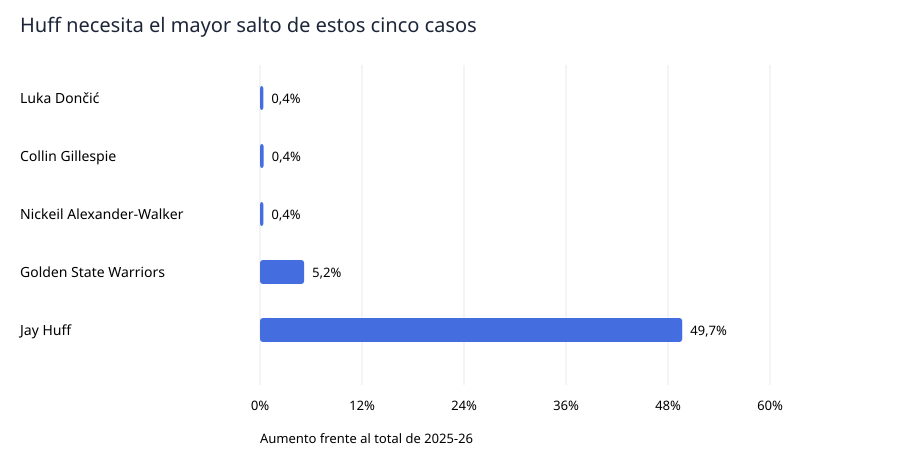

In [3]:
# calculo la diferencia con el curso anterior y separo los récords positivos de los negativos
datos['para_superarlo'] = datos['record'] + 1
datos['diferencia'] = datos['para_superarlo'] - datos['total_2025_26']
datos['cambio_total_pct'] = 100 * datos['diferencia'] / datos['total_2025_26']
datos['ritmo_anterior'] = datos['total_2025_26'] / datos['partidos_2025_26']
datos['ritmo_82'] = datos['para_superarlo'] / 82
positivos = datos.loc[datos.tipo.eq('Positivo')].copy()
negativos = datos.loc[datos.tipo.eq('Negativo')].copy()
mostrar(positivos[['protagonista','metrica','total_2025_26','record','para_superarlo','diferencia','cambio_total_pct']])

# dibujo con svg para que los gráficos queden dentro del cuaderno y no necesiten internet
def barras(tabla, etiquetas, valores, titulo, eje, limite, color='#446ddf', sufijo=''):
    alto = 165 + 58 * len(tabla)
    izquierda, ancho = 260, 510
    piezas = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 900 {alto}" role="img" aria-label="{html.escape(titulo)}">', '<rect width="900" height="100%" fill="#fff"/>', f'<text x="20" y="32" font-size="20" font-family="sans-serif" fill="#1c2638">{html.escape(titulo)}</text>']
    for i in range(6):
        valor = limite * i / 5
        x = izquierda + ancho * i / 5
        piezas.append(f'<line x1="{x}" x2="{x}" y1="65" y2="{alto-70}" stroke="#e6eaf2"/><text x="{x}" y="{alto-45}" text-anchor="middle" font-size="13" font-family="sans-serif">{valor:g}{sufijo}</text>')
    for i, (_, fila) in enumerate(tabla.iterrows()):
        y = 86 + 58 * i
        valor = float(fila[valores])
        ancho_barra = ancho * valor / limite
        etiqueta = html.escape(str(fila[etiquetas]))
        texto_valor = f'{valor:.1f}'.replace('.', ',') + sufijo
        piezas.append(f'<text x="20" y="{y+17}" font-size="14" font-family="sans-serif">{etiqueta}</text><rect x="{izquierda}" y="{y}" width="{ancho_barra}" height="24" rx="3" fill="{color}"/><text x="{izquierda+ancho_barra+8}" y="{y+17}" font-size="13" font-family="sans-serif">{texto_valor}</text>')
    piezas.append(f'<text x="{izquierda}" y="{alto-12}" font-size="13" font-family="sans-serif">{html.escape(eje)}</text></svg>')
    dibujo = ''.join(piezas)
    display(SVG(dibujo))
    return dibujo
grafico_positivos = barras(positivos,'protagonista','cambio_total_pct','Huff necesita el mayor salto de estos cinco casos','Aumento frente al total de 2025-26',60,sufijo='%')

### Lo que encuentro

Dončić, Gillespie y Alexander-Walker están en un caso especial: el récord que persiguen es suyo y acaba de nacer. Bastaría con sumar un triple más que en 2025-26. Pero ese triple llega después de repetir todos los anteriores: Dončić necesita 255 en una temporada completa, no uno al empezar octubre.

Golden State necesita 123 asistencias más que el año anterior, un aumento del 5,2%. Huff tiene un salto mucho mayor: pasar de 153 a 229 tapones exige 76 más, cerca de la mitad de su total anterior. Y ya disputó los 82 partidos: aquí no basta con añadir encuentros al calendario.

Dejo los datos de [Huff](https://www.nba.com/pacers/news/player-review-2026-jay-huff), [Alexander-Walker](https://pr.nba.com/hawks-nickeil-alexander-walker-named-2025-26-kia-nba-most-improved-player/) y [Dončić](https://www.nba.com/lakers/news/luka-doncic-earns-sixth-all-nba-first-team-honor) enlazados para seguir esas comparaciones.

## 4. Los récords que nadie quiere

Ahora cambio de lado: comparo las derrotas de los cinco últimos de 2025-26 con el peor total de cada club. En la tabla incluyo cuántas victorias como máximo dejaría una temporada que superase esa marca, siempre con 82 partidos.

En el gráfico, el punto gris muestra las derrotas del último curso y el azul las necesarias para batir el récord. Cuanto más separados estén, más tendría que empeorar el total. La distancia cuenta partidos; no cuenta la probabilidad de que suceda.

,Equipo,Total en 2025-26,Récord,Temporada del récord,Para superarlo,Diferencia con 2025-26,Victorias como máximo
0,Indiana Pacers,63,63,2025-26,64,1,18
1,Washington Wizards,65,67,2023-24,68,3,14
2,Sacramento Kings,60,65,2008-09,66,6,16
3,Utah Jazz,60,65,2024-25,66,6,16
4,Brooklyn Nets,62,70,2009-10,71,9,11


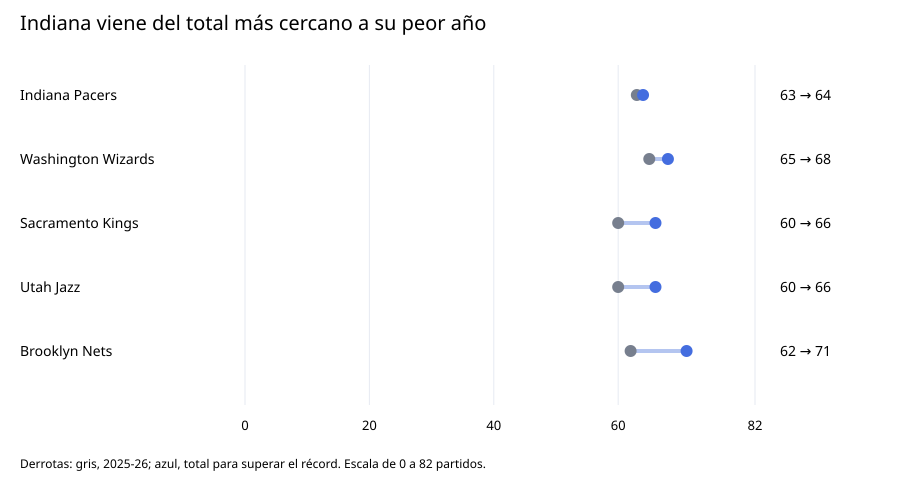

In [4]:
# traduzco cada récord negativo a derrotas y victorias dentro de 82 partidos
negativos['victorias_maximas'] = 82 - negativos['para_superarlo']
negativos['derrotas_pct'] = 100 * negativos['para_superarlo'] / 82
negativos = negativos.sort_values(['diferencia','equipo']).reset_index(drop=True)
mostrar(negativos[['equipo','total_2025_26','record','temporada_record','para_superarlo','diferencia','victorias_maximas']])

# separo el último curso del umbral histórico para que no parezcan derrotas ya acumuladas
alto = 160 + 64 * len(negativos)
izquierda, ancho = 245, 510
piezas = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 920 {alto}" role="img" aria-label="Derrotas del último curso y umbral del récord">','<rect width="920" height="100%" fill="white"/>','<text x="20" y="30" font-family="sans-serif" font-size="20">Indiana viene del total más cercano a su peor año</text>']
for marca in [0,20,40,60,82]:
    x = izquierda + ancho * marca / 82
    piezas.append(f'<line x1="{x}" x2="{x}" y1="65" y2="{alto-75}" stroke="#e6eaf2"/><text x="{x}" y="{alto-50}" text-anchor="middle" font-family="sans-serif" font-size="13">{marca}</text>')
for i, fila in negativos.iterrows():
    y = 95 + 64 * i
    x1 = izquierda + ancho * fila.total_2025_26 / 82
    x2 = izquierda + ancho * fila.para_superarlo / 82
    piezas.append(f'<text x="20" y="{y+5}" font-family="sans-serif" font-size="14">{html.escape(fila.equipo)}</text><line x1="{x1}" x2="{x2}" y1="{y}" y2="{y}" stroke="#b4c5f0" stroke-width="4"/><circle cx="{x1}" cy="{y}" r="6" fill="#777f8e"/><circle cx="{x2}" cy="{y}" r="6" fill="#446ddf"/><text x="780" y="{y+5}" font-family="sans-serif" font-size="14">{fila.total_2025_26} → {fila.para_superarlo}</text>')
piezas.append(f'<text x="20" y="{alto-12}" font-family="sans-serif" font-size="12">Derrotas: gris, 2025-26; azul, total para superar el récord. Escala de 0 a 82 partidos.</text></svg>')
grafico_negativos = ''.join(piezas)
display(SVG(grafico_negativos))

### Lo que encuentro

Indiana perdió 63 partidos: su peor total en la NBA. Una temporada con 64 derrotas lo superaría. Washington viene de 65, pero su marca está en 67, no en 65: necesitaría llegar a 68. Utah y Sacramento tendrían que pasar de 60 a 66; Brooklyn, de 62 a 71.

Son malas noticias de distinto tamaño. Los Nets necesitarían perder casi 87 de cada 100 partidos para batir su marca, más que los otros cuatro equipos de esta selección.

No convierto a Indiana en favorito al desastre por estar a una derrota: [Haliburton vuelve tras perderse 2025-26](https://www.nba.com/news/2026-27-season-preview-ind?lid=h92kmr6bgbb7). El total anterior describe lo que pasó con aquel equipo, no lo que tiene que pasar con el siguiente.

## 5. Perder 59 partidos puede ser peor que perder 73

Para comparar temporadas de distinta duración, divido las victorias entre todos los partidos. Philadelphia ganó 9 y perdió 73 en 1972-73. Charlotte ganó 7 y perdió 59 en 2011-12, cuando la liga tuvo un calendario reducido.

El total de derrotas hace parecer mucho peor a Philadelphia. El porcentaje cuenta otra cosa: cuánto costaba ganar una noche cualquiera de aquellos cursos. Calculo la proporción con los balances completos, sin copiar porcentajes redondeados.

,Equipo,Temporada,Victorias,Derrotas,Partidos,Victorias (%)
0,Philadelphia 76ers,1972-73,9,73,82,10.976
1,Charlotte Bobcats,2011-12,7,59,66,10.606


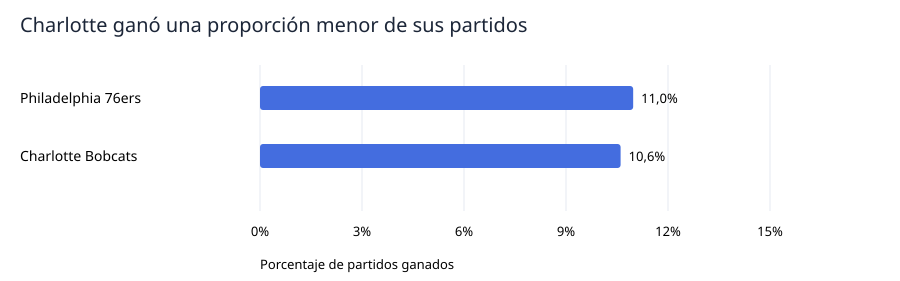

Con 82 partidos, empeorar el porcentaje de Charlotte exige 8 victorias como máximo y 74 derrotas como mínimo.


In [5]:
# comparo los balances completos para que la duración del calendario no engañe
historicas['partidos'] = historicas['victorias'] + historicas['derrotas']
historicas['victorias_pct'] = 100 * historicas['victorias'] / historicas['partidos']
display(historicas[['equipo','temporada','victorias','derrotas','partidos','victorias_pct']].rename(columns={'equipo':'Equipo','temporada':'Temporada','victorias':'Victorias','derrotas':'Derrotas','partidos':'Partidos','victorias_pct':'Victorias (%)'}).round(3))
grafico_porcentajes = barras(historicas,'equipo','victorias_pct','Charlotte ganó una proporción menor de sus partidos','Porcentaje de partidos ganados',15,sufijo='%')

# busco el número entero de victorias que quedaría por debajo de charlotte en 82 partidos
porcentaje_charlotte = 7 / 66
victorias_para_empeorarlo = max(v for v in range(83) if v / 82 < porcentaje_charlotte)
print(f'Con 82 partidos, empeorar el porcentaje de Charlotte exige {victorias_para_empeorarlo} victorias como máximo y {82-victorias_para_empeorarlo} derrotas como mínimo.')

### Lo que encuentro

Philadelphia ganó el 10,98% de sus partidos; Charlotte, el 10,61%. Los Bobcats perdieron menos veces porque jugaron menos encuentros, pero ganaron una proporción todavía menor.

En una temporada de 82 partidos, acabar con 8 victorias y 74 derrotas bastaría para superar las 73 derrotas de Philadelphia y quedar por debajo del porcentaje de Charlotte. Lo obtengo buscando balances enteros, no alargando la temporada de los Bobcats con partidos inventados.

Mantengo dos referencias distintas: **73 derrotas en una temporada** y **7 victorias en 66 partidos**. Ambas cuentan un desastre, pero no miden lo mismo.

## 6. Una mala racha tiene su propio récord

Un equipo también puede caer en la historia por perder una y otra vez sin una victoria en medio. Detroit llegó a 28 derrotas seguidas en 2023-24. Philadelphia también encadenó 28, pero repartidas entre el final de 2014-15 y el principio de 2015-16.

Para superar esas rachas harían falta 29 derrotas consecutivas. No basta con sumar 29 durante todo el año. Por eso no meto este dato en la misma columna que las derrotas de una temporada.

La [crónica que cerró la racha de Detroit](https://www.nba.com/news/pistons-beat-raptors-to-snap-losing-streak) permite distinguir los dos casos.

In [6]:
# guardo las rachas por separado porque una derrota aislada no alarga una cadena
rachas = pd.DataFrame([
    {'Equipo':'Detroit Pistons','Temporadas':'2023-24','Derrotas seguidas':28,'Alcance':'Una temporada','Para superarla':29},
    {'Equipo':'Philadelphia 76ers','Temporadas':'2014-15 y 2015-16','Derrotas seguidas':28,'Alcance':'Dos temporadas','Para superarla':29},
])
display(rachas)
rachas.to_csv(ruta / 'rachas_historicas.csv',index=False,encoding='utf-8-sig')

,Equipo,Temporadas,Derrotas seguidas,Alcance,Para superarla
0,Detroit Pistons,2023-24,28,Una temporada,29
1,Philadelphia 76ers,2014-15 y 2015-16,28,Dos temporadas,29


## 7. Detroit recuerda que un mal año no dura para siempre

Vuelvo a Detroit, esta vez para mirar temporadas completas. Comparo sus derrotas en 2023-24, 2024-25 y 2025-26. Cada barra representa un curso terminado, con 82 partidos.

Esta comparación sirve para poner en perspectiva la lista de récords negativos: un equipo que estuvo hundido puede cambiar mucho en poco tiempo.

,Temporada,Victorias,Derrotas
0,2023-24,14,68
1,2024-25,44,38
2,2025-26,60,22


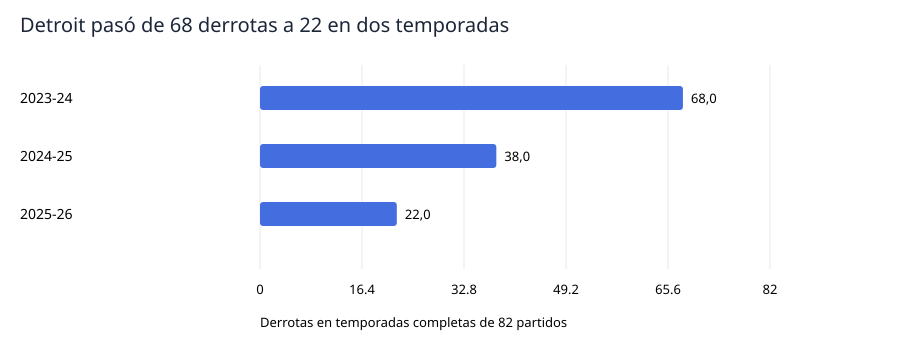

Detroit perdió 46 partidos menos entre 2023-24 y 2025-26.


In [7]:
# comparo tres temporadas observadas de detroit sin alargar la serie hacia el futuro
assert (detroit.victorias + detroit.derrotas).eq(82).all()
display(detroit[['temporada','victorias','derrotas']].rename(columns={'temporada':'Temporada','victorias':'Victorias','derrotas':'Derrotas'}))
grafico_detroit = barras(detroit,'temporada','derrotas','Detroit pasó de 68 derrotas a 22 en dos temporadas','Derrotas en temporadas completas de 82 partidos',82)
mejora_detroit = int(detroit.iloc[0].derrotas - detroit.iloc[-1].derrotas)
print(f'Detroit perdió {mejora_detroit} partidos menos entre 2023-24 y 2025-26.')

### Lo que encuentro

Detroit pasó de 14 victorias a 44 y después a 60. Perdió 46 partidos menos entre el primer y el último curso. La marca negativa sigue en sus libros, pero dejó de describir cómo terminaba su temporada.

No atribuyo todo el cambio a una sola persona. Con estos datos puedo contar el tamaño de la recuperación; para repartir las causas tendría que estudiar plantilla, minutos y juego. Es una buena razón para mirar a los equipos del fondo sin dar por hecho que repetirán su año anterior.

## 8. Qué me llevo para la segunda parte

Encuentro dos maneras muy distintas de acercarse a la historia. Dončić, Gillespie y Alexander-Walker pueden mejorar una marca propia si repiten una temporada completa y añaden un triple. Golden State necesita elevar sus asistencias algo más de un 5%; Huff, sus tapones casi un 50%.

En el otro lado, Indiana viene de su peor total de derrotas en la NBA. Washington, Utah, Sacramento y Brooklyn también tienen marcas negativas que vigilar, aunque el salto necesario no sea el mismo. La comparación de Detroit recuerda por qué la cercanía del año anterior no basta para anticipar el siguiente.

**Mi punto de partida para el artículo es este: no todos los récords se celebran, y una diferencia pequeña puede contar historias muy distintas.** El cuaderno permite comparar esas historias con cifras; no calcula quién batirá una marca.

### Hasta dónde llego

Elijo diez casos para esta continuación; no estudio todos los récords de los 30 clubes. Comparo temporadas completas y dejo fuera eliminatorias, partidos sueltos y pretemporada. Las plantillas, los minutos y la salud pueden cambiar: no los convierto en probabilidades. Las fuentes y los PDF quedan al final y junto al cuaderno para poder revisar cada cifra.

In [8]:
# compruebo las cifras principales antes de guardar las tablas para el artículo
por_id = datos.set_index('id')
assert por_id.loc['indiana','para_superarlo'] == 64
assert por_id.loc['washington','para_superarlo'] == 68
assert por_id.loc['utah','para_superarlo'] == 66
assert por_id.loc['sacramento','para_superarlo'] == 66
assert por_id.loc['brooklyn','para_superarlo'] == 71
assert por_id.loc['huff','diferencia'] == 76
assert round(por_id.loc['warriors','cambio_total_pct'],1) == 5.2
assert historicas.loc[historicas.equipo.eq('Charlotte Bobcats'),'victorias_pct'].iloc[0] < historicas.loc[historicas.equipo.eq('Philadelphia 76ers'),'victorias_pct'].iloc[0]
assert victorias_para_empeorarlo == 8 and mejora_detroit == 46
assert 9 / 82 > 7 / 66 and 8 / 82 < 7 / 66
datos.to_csv(ruta / 'comparacion_segunda_parte.csv',index=False,encoding='utf-8-sig')
negativos.to_csv(ruta / 'records_negativos.csv',index=False,encoding='utf-8-sig')
positivos.to_csv(ruta / 'records_positivos.csv',index=False,encoding='utf-8-sig')

# conservo las huellas de los datos y las guías para reconocer los archivos utilizados
archivos = ['records_segunda_parte.csv','temporadas_historicas.csv','evolucion_detroit.csv','auditoria_fuentes.csv']
archivos += sorted(str(p.relative_to(ruta)).replace('\\','/') for p in (ruta / 'fuentes').glob('*.pdf'))
huellas = {nombre:hashlib.sha256((ruta / nombre).read_bytes()).hexdigest() for nombre in archivos}
(ruta / 'huellas_archivos.json').write_text(json.dumps(huellas,indent=2),encoding='utf-8')
for nombre, dibujo in [('positivos',grafico_positivos),('negativos',grafico_negativos),('porcentajes',grafico_porcentajes),('detroit',grafico_detroit)]:
    (ruta / f'grafico_{nombre}.svg').write_text(dibujo,encoding='utf-8')
print('He comprobado las cifras y guardado las tablas. Los cuatro gráficos quedan dentro del notebook.')

He comprobado las cifras y guardado las tablas. Los cuatro gráficos quedan dentro del notebook.

## Fuentes para seguir leyendo

Dejo los enlaces agrupados por caso en la tabla siguiente. En `fuentes/` guardo las guías de Indiana y Golden State y las notas de cierre de Indiana, Golden State, Utah y Washington. Las páginas web están enlazadas en el CSV; no hacen falta para ejecutar el cuaderno.

Para repetir el análisis, abro este notebook desde su carpeta y ejecuto todas las celdas. Necesito Python, pandas e IPython.

In [9]:
# convierto las referencias en enlaces para poder abrir cada fuente desde el cuaderno
filas = []
for _, fila in fuentes.iterrows():
    copia = f'<a href="{html.escape(fila.copia_local)}">PDF guardado</a>' if fila.copia_local else 'Web'
    filas.append(f'<tr><td>{html.escape(fila.id_fuente)}</td><td><a href="{html.escape(fila.url)}">{html.escape(fila.fuente)}</a></td><td>{html.escape(fila.dato)}</td><td>{copia}</td></tr>')
display(HTML('<table><thead><tr><th>Referencia</th><th>Fuente</th><th>Dato utilizado</th><th>Copia</th></tr></thead><tbody>'+''.join(filas)+'</tbody></table>'))

Referencia,Fuente,Dato utilizado,Copia
luka,Los Angeles Lakers: balance de Dončić 2025-26,"254 triples, récord del club; 64 partidos.",Web
gillespie,NBA: previa de Phoenix 2026-27,"232 triples, récord del club en 2025-26.",Web
gillespie_partidos,NBA: renovación de Gillespie,80 partidos en 2025-26; renovación para 2026-27.,Web
nickeil,NBA Communications: premio a Alexander-Walker,"251 triples, récord de Atlanta; 78 partidos en 2025-26.",Web
huff,Indiana Pacers: balance de Jay Huff,153 tapones en 82 partidos en 2025-26.,Web
indiana_guia,Indiana Pacers: guía 2025-26,"Tabla NBA de tapones: 228 de Jermaine O’Neal, 2000-01.",PDF guardado
indiana_notas,Indiana Pacers: notas de cierre 2025-26,19 victorias y 63 derrotas; estadísticas de todos los jugadores en 2025-26.,PDF guardado
warriors_historia,Golden State Warriors: guía 2023-24,Récord colectivo de 2.491 asistencias en 2016-17; página PDF 153.,PDF guardado
warriors_actual,Golden State Warriors: cierre 2025-26,2.369 asistencias en 82 partidos.,PDF guardado
warriors_series,Basketball-Reference: temporadas de Golden State,Serie histórica del radar original; cotejo del récord con la guía oficial. Fuente secundaria.,Web
